# Jordanian PC Builder — Phase 2 training notebook


## 1. Install dependencies


In [1]:
%pip -q install "transformers>=4.50,<5" "accelerate>=1,<2" "pymupdf>=1.24" "pandas>=2" "matplotlib>=3.7" "sentencepiece>=0.2"

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.


## 2. Data & Configuration


###2.1 Calling the data

In [2]:
!pip install gitpython -q

import git
from pathlib import Path
from google.colab import drive

# 1. Mount Google Drive
drive.mount('/content/drive')

# 2. Read the token from the shared text file
token_path = Path('/content/drive/MyDrive/Tokens/github-token.txt')
shared_token = token_path.read_text().strip()

# 3. Define the repository details and inject the token
repo_url = f"https://{shared_token}@github.com/Sulieman25/Jordanian-PC-Builder---DS493.git"
base_dir = Path("/content")
repo_name = "Jordanian-PC-Builder---DS493"
repo_path = base_dir / repo_name

# 4. Clone the repo
if not repo_path.exists():
    print(f"Cloning {repo_name}...")
    git.Repo.clone_from(repo_url, str(repo_path))
else:
    print(f"{repo_name} is already cloned.")

# 5. Assign paths to variables
DATA_PATH = repo_path / "data"
CPT_DATA_PATH = DATA_PATH / "cpt"
SRC_PATH = repo_path / "src"
RESULTS_PATH = repo_path / "results"
TESTS_PATH = repo_path / "tests"
CONFIG_PATH = repo_path / "config.yaml"
CSV_PATH = DATA_PATH / "components.csv"
TEST_CSV_PATH = TESTS_PATH / "test_questions.csv"
VERIFIED_QA_PATH = DATA_PATH / "sft_verified.jsonl"

# 6. Map the variables needed for the rest of the notebook
OUTPUT_DIR = RESULTS_PATH

ARTICLE_DIR = DATA_PATH

# 7. Automatically discover all PDF articles
ARTICLE_PATHS = sorted(DATA_PATH.glob("*.pdf"))

# 8. Verify files
assert DATA_PATH.exists(), f"Folder not found: {DATA_PATH}"
assert CSV_PATH.exists(), f"CSV not found: {CSV_PATH}"

# 9. Print summaries
print("Repository cloned and paths assigned successfully.")
print(f"Components CSV: {CSV_PATH.name}")
print(f"Articles found: {len(ARTICLE_PATHS)}")

for article in ARTICLE_PATHS:
    print(article.name)

if len(ARTICLE_PATHS) != 15:
    print("Warning: Expected 15 PDF articles.")

Mounted at /content/drive
Cloning Jordanian-PC-Builder---DS493...
Repository cloned and paths assigned successfully.
Components CSV: components.csv
Articles found: 14
Best Graphics Cards for Gaming in 2026 _ Tom_s Hardware.pdf
Best cheap gaming PC deals _ PC Gamer.pdf
Best gaming PC builds_ Shop all our recommended system builds as we ride out the RAMpocalypse _ PC Gamer.pdf
Best gaming PCs in 2026_ We_ve tested the best current-gen gaming PCs and these are our picks _ PC Gamer.pdf
Buying PC Components_ Compatibility, Specs and Common Pitfalls.pdf
Choose a Processor - OpenClassrooms.pdf
Design Your Dream PC with CORSAIR _ CORSAIR.pdf
How do I check if parts go together_ PC Compatibility Guide.pdf
How to Build a PC (2025)_ Hardware Suggestions, Instructions, and More _ WIRED.pdf
How to Choose a Motherboard and Compatible PC Parts Guide.pdf
How to Choose a PC Case for Your Build_ Steps & Checklist.pdf
How to Choose a Power Supply for Your PC_ Steps & Checklist.pdf
How to build a PC in 20

###2.2 Configuration

In [3]:
#-----------[MODEL CONFIGURATION]-----------

import yaml

# 1. Load the YAML file
with open(CONFIG_PATH, "r") as file:
    config = yaml.safe_load(file)

MODEL_NAME = config["MODEL_NAME"]
SEED = config["SEED"]

# CONTINUED PRETRAINING (CPT)
BLOCK_SIZE = config["BLOCK_SIZE"]
CATALOG_ROWS_PER_DOCUMENT = config["CATALOG_ROWS_PER_DOCUMENT"]
CPT_EPOCHS = config["CPT_EPOCHS"]
CPT_LR = float(config["CPT_LR"])

# SUPERVISED FINE-TUNING (SFT)
SFT_EPOCHS = config["SFT_EPOCHS"]
SFT_LR = float(config["SFT_LR"])
SFT_MAX_LENGTH = config["SFT_MAX_LENGTH"]
SFT_TARGET_CATALOG_PAIRS = config["SFT_TARGET_CATALOG_PAIRS"]

# TRAINING SETTINGS
TRAIN_BATCH_SIZE = config["TRAIN_BATCH_SIZE"]
GRADIENT_ACCUMULATION = config["GRADIENT_ACCUMULATION"]
EVAL_BATCH_SIZE = config["EVAL_BATCH_SIZE"]
MAX_TRAIN_STEPS = config["MAX_TRAIN_STEPS"]

# GENERATION SETTINGS
GEN_MAX_NEW_TOKENS = config["GEN_MAX_NEW_TOKENS"]

# CONFIGURATION SUMMARY
print("Model:", MODEL_NAME)
print("CPT epochs:", CPT_EPOCHS)
print("SFT epochs:", SFT_EPOCHS)
print("Block size:", BLOCK_SIZE)

Model: gpt2
CPT epochs: 10
SFT epochs: 10
Block size: 512


## 3. Connect data and fix the random seed


In [ ]:
#-----------[IMPORTS & ENVIRONMENT SETUP]-----------

import gc, json, math, random, re
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from IPython.display import display
from transformers import set_seed

# Reproducibility
set_seed(SEED)

# GPU availability
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))


Device: cuda
GPU: Tesla T4


##4. Cleaning, Loading & Converting Data

###4.1 Load and clean `components.csv`
Excluding rows with invalid prices from training.

In [ ]:
#-----------[LOAD & CLEAN COMPONENTS]-----------

# Load catalogue
catalog = pd.read_csv(CSV_PATH)
original_count = len(catalog)

# Clean text columns
for col in ["store", "category", "product_name", "product_url"]:
    catalog[col] = catalog[col].fillna("").astype(str).str.strip()

# Convert prices to numeric
catalog["price_jod"] = pd.to_numeric(
    catalog["price_jod"], errors="coerce"
)

# Remove invalid products
catalog = catalog[
    (catalog["price_jod"] > 0) &
    (catalog["product_name"] != "") &
    (catalog["product_url"].str.startswith(("http://", "https://")))
]

# Remove duplicates, keeping the most recent listing
catalog = (
    catalog.sort_values("collected_at_utc")
    .drop_duplicates(subset="product_url", keep="last")
    .reset_index(drop=True)
)

# Summary
print("Original products:", original_count)
print("Usable products:", len(catalog))
print("Removed products:", original_count - len(catalog))

display(catalog["category"].value_counts())
display(catalog.head())


Original products: 2250
Usable products: 2245
Removed products: 5


,count
category,
GPU,445
Motherboard,408
Case,300
PSU,227
RAM,180
CPU,158
Liquid Cooling,147
SSD,144
Case Fan,77


,store,category,product_name,price_jod,product_url,collected_at_utc
0,Oriental Store,CPU,Intel Core Ultra 5 250KF Plus Processor (Serie...,259.0,https://os-jo.com/intel-core-ultra-5-250kf-plu...,2026-10-31T09:21:03+00:00
1,Oriental Store,CPU,AMD RYZEN 9 9900X Up to 5.6GHz 12 Cores 24 thr...,379.0,https://os-jo.com/amd-ryzen-9-9900x-up-to-5-6g...,2026-10-31T09:21:03+00:00
2,Oriental Store,CPU,AMD RYZEN 7 9700X Up to 5.5GHz 8 Cores 16 thre...,269.0,https://os-jo.com/amd-ryzen-7-9700x-up-to-5-5g...,2026-10-31T09:21:03+00:00
3,Oriental Store,CPU,AMD RYZEN 5 8400F Up to 4.7GHz 6 Cores 12 thre...,99.0,https://os-jo.com/amd-ryzen-5-8400f-up-to-4-7g...,2026-10-31T09:21:03+00:00
4,Oriental Store,CPU,AMD RYZEN 7 7700X Up To 5.4GHz 8 Cores 16 Thre...,219.0,https://os-jo.com/amd-ryzen-7-7700x-up-to-5-4g...,2026-10-31T09:21:03+00:00


###4.2 Extract *only* compatibility/article PDFs


In [ ]:
#-----------[EXTRACT & CLEAN PDF ARTICLES]-----------

import pymupdf

#Clean extracted PDF text
def clean_pdf_text(text):

    #Remove invisible characters and website icons
    text = re.sub(r"[\x00\u00ad\uE000-\uF8FF]", " ", text)

    #Remove URLs and webpage timestamps
    text = re.sub(r"https?://\S+", " ", text)
    text = re.sub(
        r"(?m)^\s*\d{1,2}/\d{1,2}/\d{2,4},?\s+\d{1,2}:\d{2}\s*[AP]M",
        "", text
    )

    #Remove common website navigation
    text = re.sub(
        r"\b(?:SIGN IN|WISHLIST|CART|Cookie Policy|I agree|Only essentials)\b",
        " ", text, flags=re.IGNORECASE
    )

    #Remove common cookie notice
    text = re.sub(
        r"We use cookies to provide you a better user experience on this\s+website\.?",
        " ", text, flags=re.IGNORECASE
    )

    #Repair broken words and normalize whitespace
    text = re.sub(r"(?<=\w)-\n(?=\w)", "", text)
    text = re.sub(r"[ \t]+", " ", text)
    text = re.sub(r"\n{3,}", "\n\n", text)

    return text.strip()


#Extract PDF articles
article_docs = []

for path in ARTICLE_PATHS:
    with pymupdf.open(path) as pdf:
        text = "\n".join(
            page.get_text("text", sort=True)
            for page in pdf
        )

    text = clean_pdf_text(text)

    if len(text) < 400:
        print("Skipped (insufficient text):", path.name)
        continue

    article_docs.append({
        "kind": "article",
        "source": path.name,
        "text": text
    })


#Summary
print("PDFs found:", len(ARTICLE_PATHS))
print("Articles extracted:", len(article_docs))

for article in article_docs:
    print(article["source"], "-", len(article["text"]), "characters")

if article_docs:
    print("\nSample text:\n", article_docs[0]["text"][:500])


PDFs found: 14
Articles extracted: 14
Best Graphics Cards for Gaming in 2026 _ Tom_s Hardware.pdf - 51912 characters
Best cheap gaming PC deals _ PC Gamer.pdf - 24737 characters
Best gaming PC builds_ Shop all our recommended system builds as we ride out the RAMpocalypse _ PC Gamer.pdf - 16915 characters
Best gaming PCs in 2026_ We_ve tested the best current-gen gaming PCs and these are our picks _ PC Gamer.pdf - 46209 characters
Buying PC Components_ Compatibility, Specs and Common Pitfalls.pdf - 9347 characters
Choose a Processor - OpenClassrooms.pdf - 13703 characters
Design Your Dream PC with CORSAIR _ CORSAIR.pdf - 13928 characters
How do I check if parts go together_ PC Compatibility Guide.pdf - 17746 characters
How to Build a PC (2025)_ Hardware Suggestions, Instructions, and More _ WIRED.pdf - 48604 characters
How to Choose a Motherboard and Compatible PC Parts Guide.pdf - 1063 characters
How to Choose a PC Case for Your Build_ Steps & Checklist.pdf - 11018 characters
How to Ch

###4.3 Convert real catalogue records into plain text


In [ ]:
#-----------[CONVERT CATALOGUE TO TEXT]-----------

#Convert each product into readable text
def product_as_text(row):
    return (
        f"Category: {row['category']}\n"
        f"Product: {row['product_name']}\n"
        f"Store: {row['store']}\n"
        f"Price: {row['price_jod']:.2f} JOD"
    )


#Shuffle products reproducibly
products = catalog.to_dict("records")
random.Random(SEED).shuffle(products)

#Group products into training documents
catalog_docs = []

for i in range(0, len(products), CATALOG_ROWS_PER_DOCUMENT):
    batch = products[i:i + CATALOG_ROWS_PER_DOCUMENT]

    catalog_docs.append({
        "kind": "catalog",
        "source": f"catalog_batch_{i // CATALOG_ROWS_PER_DOCUMENT}",
        "text": "\n\n".join(product_as_text(row) for row in batch),
        "products": batch
    })


#Preview
print("Catalogue documents:", len(catalog_docs))
print("\nSample training text:\n")
print(catalog_docs[0]["text"][:600])

Catalogue documents: 38

Sample training text:

Category: Motherboard
Product: ASROCK X570 Phantom Gaming 4 ATX Motherboard
Store: Oriental Store
Price: 149.00 JOD

Category: SSD
Product: Kingston Dual Portable SSD (1TB) USB 3.2 Gen 2 (USB Type-A and Type-C) Portable External Solid State Drive (SSD) Up to Up to 1,050MB/s Read, 950MB/s Write
Store: Oriental Store
Price: 129.00 JOD

Category: Case
Product: Lian Li O11 Dynamic XL ROG Certified (Silver) Mid Tower Tempered Glass Gaming Case w/ ARGB Front Bar
Store: Oriental Store
Price: 169.00 JOD

Category: PSU
Product: Cooler Master V850 Gold V2 Full Modular Power Supply, 850W, 80+ Gold Effici


## 5. Document-level train/held-out split - 90/10 target
We split PDFs and catalogue batches **independently** so validation includes both source types. With very few PDFs, keeping one complete PDF held out may make the article fraction larger than 10%; that is better than splitting pages from one article between sets.

Products from held-out catalogue batches are **not** used to create SFT training examples.

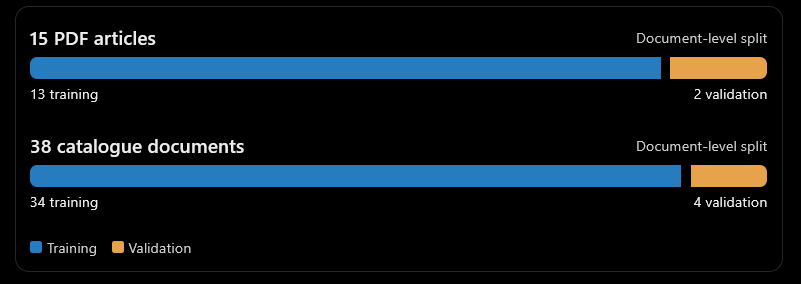

In [ ]:
#-----------[TRAIN / VALIDATION SPLIT]-----------

#Split documents into 90% training and 10% validation
def split_documents(docs, seed):
    shuffled = docs.copy()
    random.Random(seed).shuffle(shuffled)

    n_val = max(1, round(len(shuffled) * 0.10))
    return shuffled[n_val:], shuffled[:n_val]


#Split articles and catalogue separately
train_article_docs, val_article_docs = split_documents(article_docs, SEED)
train_catalog_docs, val_catalog_docs = split_documents(catalog_docs, SEED + 1)

#Combine documents for CPT
train_docs = train_article_docs + train_catalog_docs
val_docs = val_article_docs + val_catalog_docs

#Extract product records for SFT
train_products = [
    product
    for doc in train_catalog_docs
    for product in doc["products"]
]

val_products = [
    product
    for doc in val_catalog_docs
    for product in doc["products"]
]

#Summary
print(f"Articles: {len(train_article_docs)} train / {len(val_article_docs)} validation")
print(f"Catalogue: {len(train_catalog_docs)} train / {len(val_catalog_docs)} validation")
print(f"Total: {len(train_docs)} train / {len(val_docs)} validation")
print(f"Products: {len(train_products)} train / {len(val_products)} validation")


Articles: 13 train / 1 validation
Catalogue: 34 train / 4 validation
Total: 47 train / 5 validation
Products: 2005 train / 240 validation


## 6. Load tokenizer and prepare fixed-length next-token sequences
Model choice is set in **one** configuration cell. We use the model's existing EOS as the padding token where a separate padding token is absent. Small incomplete remainders are not mixed between train and held-out sets.

###6.1 Tokenizer

In [ ]:
#-----------[LOAD TOKENIZER & BASE MODEL]-----------

from transformers import AutoTokenizer, AutoModelForCausalLM

#Load tokenizer
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

#Set padding token if missing
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

#Load pretrained model
base_model = AutoModelForCausalLM.from_pretrained(MODEL_NAME)
base_model.config.pad_token_id = tokenizer.pad_token_id
base_model.to(DEVICE)

#Summary
print("Model:", MODEL_NAME)
print("Parameters:", f"{sum(p.numel() for p in base_model.parameters()):,}")


Model: gpt2
Parameters: 124,439,808


###6.2 Packing Documents for Continued Pretraining (CPT)

Take PC-Building Documents and turn them into training examples that the model can learn from.



1. Convert documents into token sequences.

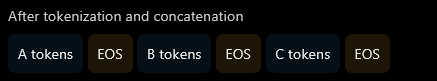


2.   Package those sequences into a PyTorch dataset.

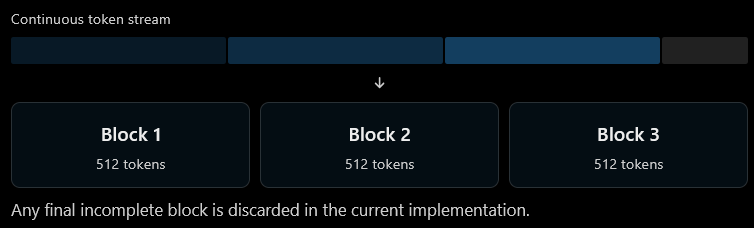



3. Create separate training and validation datasets.



In [ ]:
#-----------[PACK DOCUMENTS FOR CPT]-----------

from torch.utils.data import Dataset

#Convert documents into token blocks
def pack_documents(documents, tokenizer, block_size):
    tokens = []

    for doc in documents:
        tokens.extend(
            tokenizer.encode(doc["text"], add_special_tokens=False)
        )
        tokens.append(tokenizer.eos_token_id)

    blocks = [
        tokens[i:i + block_size]
        for i in range(0, len(tokens) - block_size + 1, block_size)
    ]

    return blocks, len(tokens)


#PyTorch dataset for causal language modeling (Make the sequence usable by PyTorch)
class CPTDataset(Dataset):
    def __init__(self, blocks):
        self.blocks = blocks

    def __len__(self):
        return len(self.blocks)

    def __getitem__(self, idx):
        tokens = torch.tensor(self.blocks[idx], dtype=torch.long)

        return {
            "input_ids": tokens,
            "attention_mask": torch.ones_like(tokens),
            "labels": tokens.clone()
        }


#Tokenize training and validation documents separately
train_blocks, train_token_count = pack_documents(
    train_docs, tokenizer, BLOCK_SIZE
)

heldout_blocks, heldout_token_count = pack_documents(
    val_docs, tokenizer, BLOCK_SIZE
)

#Create datasets
cpt_train_ds = CPTDataset(train_blocks)
cpt_val_ds = CPTDataset(heldout_blocks)

#Summary
print("Training tokens:", train_token_count)
print("Validation tokens:", heldout_token_count)
print("Training sequences:", len(cpt_train_ds))
print("Validation sequences:", len(cpt_val_ds))


Token indices sequence length is longer than the specified maximum sequence length for this model (9675 > 1024). Running this sequence through the model will result in indexing errors


Training tokens: 176091
Validation tokens: 24656
Training sequences: 343
Validation sequences: 48


E.g.: `cpt_train_ds[0]` should return the first 512-token training example



> `input_ids`	The actual token IDs the model reads

>`attention_mask`	Tells the model which positions contain valid tokens

>`labels`	The correct tokens used to compute the training loss



## 7. Base-model checkpoint & Evaluation


Baseline experiment before it learns anything from our data.

It performs two evaluations:
1. Perplexity: How well can the model predict text from our held-out `PCBuilding Data`.
2. Text generation: What does the model produce when given five `PCBuilding` prompts?


In [ ]:
#-----------[BASE MODEL EVALUATION]-----------

from torch.utils.data import DataLoader


#Calculate loss and perplexity on held-out data
@torch.no_grad() #Don't calculate gradients, we're not updating model weights (training)

def evaluate_model_perplexity(model, dataset, batch_size=2, collate_fn=None):
    model.eval()

    loader = DataLoader(dataset, batch_size=batch_size, collate_fn=collate_fn)

    total_loss_sum = 0.0
    total_valid_tokens = 0

    for batch in loader:
        batch = {k: v.to(DEVICE) for k, v in batch.items()}

        outputs = model(**batch)
        batch_loss = outputs.loss.item()

        valid_tokens_in_batch = (batch["labels"] != -100).sum().item()

        if valid_tokens_in_batch > 0:
            total_loss_sum += batch_loss * valid_tokens_in_batch
            total_valid_tokens += valid_tokens_in_batch

    if total_valid_tokens == 0:
        return {"loss": float('nan'), "perplexity": float('nan')}

    avg_loss = total_loss_sum / total_valid_tokens

    return {
        "loss": avg_loss,
        "perplexity": math.exp(avg_loss)
    }
#Generate text using greedy decoding
@torch.no_grad()
def complete_prompt(model, tok, prompt, max_new_tokens=GEN_MAX_NEW_TOKENS):
    model.eval()

    inputs = tok(prompt, return_tensors="pt").to(DEVICE)

    outputs = model.generate(
        **inputs,
        max_new_tokens=max_new_tokens,
        do_sample=False,
        eos_token_id=tok.eos_token_id,
        pad_token_id=tok.pad_token_id
    )

    generated = outputs[0, inputs["input_ids"].shape[1]:]

    return tok.decode(generated, skip_special_tokens=True).strip()


#Fixed prompts for comparison before and after CPT
CONTINUATION_PROMPTS = [
    "CPU and motherboard compatibility depends on",
    "DDR4 and DDR5 memory are different because",
    "When choosing a power supply for a gaming PC,",
    "A PC case must support the motherboard",
    "Before assembling a computer, it is important to"
]


#Evaluate base model
base_metrics = evaluate_model_perplexity(base_model, cpt_val_ds)

print("Base loss:", round(base_metrics["loss"], 4))
print("Base perplexity:", round(base_metrics["perplexity"], 4))


#Generate baseline completions
base_continuations = [
    complete_prompt(base_model, tokenizer, prompt)
    for prompt in CONTINUATION_PROMPTS
]


#Display and save results
baseline_results = pd.DataFrame({
    "Prompt": CONTINUATION_PROMPTS,
    "Base Response": base_continuations
})

display(baseline_results)

baseline_results.to_csv(
    OUTPUT_DIR / "base_continuations.csv",
    index=False
)


Base loss: 3.9329
Base perplexity: 51.0544


,Prompt,Base Response
0,CPU and motherboard compatibility depends on,the motherboard.\n\nThe following table lists ...
1,DDR4 and DDR5 memory are different because,they are different in that they are different ...
2,"When choosing a power supply for a gaming PC,",you should consider the following factors:\n\n...
3,A PC case must support the motherboard,"'s operating system, and the motherboard must ..."
4,"Before assembling a computer, it is important to",understand the basic concepts of the computer....


## 8. Continued Pretraining (CPT) - next-token prediction


In [ ]:
#-----------[CONTINUED PRETRAINING]-----------

from transformers import Trainer, TrainingArguments, EarlyStoppingCallback

#Select GPU precision <Conserves memory for Colab GPUs>
AMP_BF16 = DEVICE.type == "cuda" and torch.cuda.is_bf16_supported()
AMP_FP16 = DEVICE.type == "cuda" and not AMP_BF16

#Training configuration
cpt_args = TrainingArguments(
    output_dir=str(OUTPUT_DIR / "cpt_checkpoints"),

    #Hyperparameters
    num_train_epochs=CPT_EPOCHS, #Passes over training data
    max_steps=MAX_TRAIN_STEPS,
    learning_rate=CPT_LR, #Controls size of weight updates
    per_device_train_batch_size=TRAIN_BATCH_SIZE, #Process this many sequences per batch
    per_device_eval_batch_size=EVAL_BATCH_SIZE, #Evaluate this many sequences at a time
    gradient_accumulation_steps=GRADIENT_ACCUMULATION,

    #Logging, evaluation and checkpoints
    logging_steps=10,
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=3,

    #Select best checkpoint
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",

    #GPU precision
    bf16=AMP_BF16,
    fp16=AMP_FP16,

    seed=SEED,
    report_to="none"
)

#Disable caching during training
base_model.config.use_cache = False

#Initialize trainer
cpt_trainer = Trainer(
    model=base_model, #Chosen baseline model with its original pretrained weights
    args=cpt_args,
    train_dataset=cpt_train_ds,
    eval_dataset=cpt_val_ds,
    processing_class=tokenizer, #To convert between text and token IDs
    callbacks=[EarlyStoppingCallback(early_stopping_patience=1)]
)

# Train the model
cpt_trainer.train()

#Restore caching
base_model.config.use_cache = True

#Save trained model
CPT_MODEL_PATH = OUTPUT_DIR / "cpt_model"
cpt_trainer.save_model(str(CPT_MODEL_PATH))

#Save training history
cpt_history = cpt_trainer.state.log_history

with open(OUTPUT_DIR / "cpt_history.json", "w") as f:
    json.dump(cpt_history, f, indent=2)

print("CPT completed.")
print("Model saved to:", CPT_MODEL_PATH)


The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'pad_token_id': 50256}.


Epoch,Training Loss,Validation Loss
1,2.622200,2.648514
2,2.230000,2.489810
3,2.109200,2.428539
4,2.064600,2.399195
5,1.886600,2.379075
6,1.788600,2.373015
7,1.772600,2.364639
8,1.743200,2.356367
9,1.688400,2.352745
10,1.712700,2.353888


There were missing keys in the checkpoint model loaded: ['lm_head.weight'].


CPT completed.
Model saved to: /content/Jordanian-PC-Builder---DS493/results/cpt_model


Both training and validation loss decreased significantly overall, indicating the model successfully learned the data. .

## 9. Inspect CPT results and compare the original five prompts

Base perplexity: 51.054
CPT perplexity: 10.563


,Prompt,Base Model,After CPT
0,CPU and motherboard compatibility depends on,the motherboard.\n\nThe following table lists ...,the type of motherboard and chipset.\n\nThe mo...
1,DDR4 and DDR5 memory are different because,they are different in that they are different ...,they are not interchangeable.\n\nThe DDR5 memo...
2,"When choosing a power supply for a gaming PC,",you should consider the following factors:\n\n...,it is important to consider the following fact...
3,A PC case must support the motherboard,"'s operating system, and the motherboard must ...",’s’s’s’s’s’s’s’s’s’s’s’s’s’s’s’s’s’s’s’s’s’s\n...
4,"Before assembling a computer, it is important to",understand the basic concepts of the computer....,know the operating system and the operating sy...


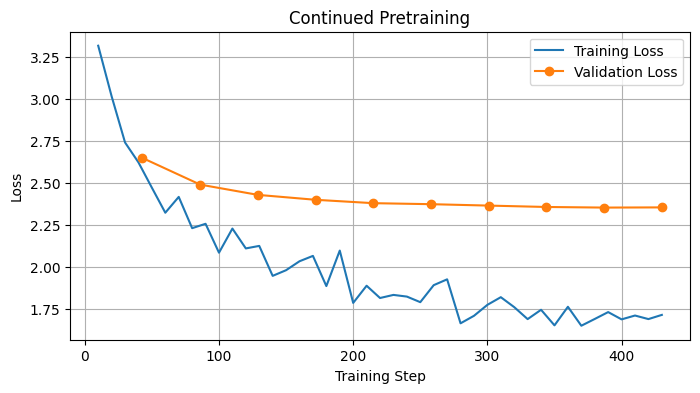

In [ ]:
#-----------[EVALUATE CPT RESULTS]-----------

#Evaluate perplexity after CPT
cpt_metrics = evaluate_model_perplexity(base_model, cpt_val_ds)

print("Base perplexity:", round(base_metrics["perplexity"], 3))
print("CPT perplexity:", round(cpt_metrics["perplexity"], 3))


#Compare responses before and after CPT
cpt_continuations = [
    complete_prompt(base_model, tokenizer, prompt)
    for prompt in CONTINUATION_PROMPTS
]

comparison = pd.DataFrame({
    "Prompt": CONTINUATION_PROMPTS,
    "Base Model": base_continuations,
    "After CPT": cpt_continuations
})

display(comparison)
comparison.to_csv(OUTPUT_DIR / "cpt_comparison.csv", index=False)


#Plot training and validation loss
history = pd.DataFrame(cpt_history)

train_history = history.dropna(subset=["loss"])
val_history = history.dropna(subset=["eval_loss"])

plt.figure(figsize=(8, 4))

plt.plot(
    train_history["step"],
    train_history["loss"],
    label="Training Loss"
)

plt.plot(
    val_history["step"],
    val_history["eval_loss"],
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Training Step")
plt.ylabel("Loss")
plt.title("Continued Pretraining")
plt.legend()
plt.grid(True)

plt.savefig(OUTPUT_DIR / "cpt_loss.png", dpi=150, bbox_inches="tight")
plt.show()


## 10. Prepare SFT Q&A pairs (source-backed, not invented)


In [ ]:
#-----------[10. LOAD & SPLIT SFT DATASET]-----------

# Load all 500 question-answer pairs
SFT_PATH = DATA_PATH / "sft_pairs.jsonl"

with open(SFT_PATH, encoding="utf-8") as f:
    sft_pairs = [json.loads(line) for line in f if line.strip()]

# Shuffle the pairs reproducibly
shuffled_pairs = sft_pairs.copy()
random.Random(SEED).shuffle(shuffled_pairs)

# Split into 90% training and 10% validation
val_count = max(1, round(len(shuffled_pairs) * 0.10))

sft_val_pairs = shuffled_pairs[:val_count]
sft_train_pairs = shuffled_pairs[val_count:]

# Summary
print("Total SFT pairs:", len(sft_pairs))
print("Training pairs:", len(sft_train_pairs))
print("Validation pairs:", len(sft_val_pairs))

display(pd.DataFrame(sft_train_pairs)[["question", "answer", "type"]].head())

Total SFT pairs: 500
Training pairs: 450
Validation pairs: 50


,question,answer,type
0,I own an AM4 Ryzen 5000 chip. Can I put it int...,No. AM4 and AM5 are different CPU sockets; sel...,technical_article
1,The case box lists E-ATX support. Is that enou...,Not always. Compare the exact board dimensions...,technical_article
2,What basic tools does the guide say you need t...,"Phillips head screwdrivers (#1 and #2), someth...",technical_article
3,How much would PNY NVIDIA Quadro T1000 8GB and...,798.00 JOD (329.00 + 469.00). This is a catalo...,catalog_build_basket_total
4,Why inspect a case’s fan layout?,"Fan size, position, and intake/exhaust layout ...",technical_article


## 13. Inspect Q&A candidates and split SFT pairs 90/10


In [ ]:
#-----------[VERIFY NO TEST-SET LEAKAGE & SAVE SFT SPLITS]-----------

# 1. Load official 30 test questions
official_test = pd.read_csv(TEST_CSV_PATH, encoding="latin-1")


print(f"Loaded {len(official_test)} official test questions.")

import difflib
# 1. Basic normalization to help the matcher
def normalize_text(t):
    return re.sub(r"\s+", " ", str(t).strip().lower())

# Create a list of normalized test questions
test_q_list = [normalize_text(q) for q in official_test["question"]]

# 2. Near-duplicate checker (85% similarity threshold)
def is_near_duplicate(q):
    norm_q = normalize_text(q)
    # Returns True if it finds at least 1 match in the test set > 85% similar
    return len(difflib.get_close_matches(norm_q, test_q_list, n=1, cutoff=0.85)) > 0

# 3. Filter out any SFT pair that is a near-duplicate
sft_train_pairs = [p for p in sft_train_pairs if not is_near_duplicate(p["question"])]
sft_val_pairs = [p for p in sft_val_pairs if not is_near_duplicate(p["question"])]

# 4. Save splits to OUTPUT_DIR
with open(OUTPUT_DIR / "sft_train.jsonl", "w", encoding="utf-8") as f:
    for pair in sft_train_pairs:
        f.write(json.dumps(pair, ensure_ascii=False) + "\n")

with open(OUTPUT_DIR / "sft_val.jsonl", "w", encoding="utf-8") as f:
    for pair in sft_val_pairs:
        f.write(json.dumps(pair, ensure_ascii=False) + "\n")

print(f"Verified SFT splits saved: {len(sft_train_pairs)} train | {len(sft_val_pairs)} validation")

Loaded 30 official test questions.
Verified SFT splits saved: 450 train | 50 validation


## 14. Define model-independent SFT chat format with **answer-only** loss
GPT-2 does not have a standard chat format. To support both GPT-2 and other causal LMs consistently, we add three explicit markers and mask question/prompt tokens with `-100` in the training labels. **Only the answer and end marker contribute to SFT loss**.

This is deliberately implemented with `Trainer` rather than version-sensitive SFT trainer options.

In [ ]:
from transformers import AddedToken

# 1. Register chat markers safely
CHAT_MARKERS = [
    AddedToken("<|user|>", lstrip=False, rstrip=False, special=True),
    AddedToken("<|assistant|>", lstrip=False, rstrip=False, special=True),
    AddedToken("<|end|>", lstrip=False, rstrip=False, special=True)
]
tokenizer.add_special_tokens({"additional_special_tokens": CHAT_MARKERS})

# 2. Resize with mean_resizing=True to prevent random noise embeddings for the added tags(user,assistant,end)
base_model.resize_token_embeddings(len(tokenizer), mean_resizing=True)
base_model.config.pad_token_id = tokenizer.pad_token_id

END_TOKEN_ID = tokenizer.convert_tokens_to_ids("<|end|>")
assert END_TOKEN_ID != tokenizer.unk_token_id, "<|end|> was not registered in the tokenizer!"

def encode_sft_pair(pair, tok, max_len):
    # Strip whitespace to prevent formatting artifacts
    prompt = f"<|user|>\n{pair['question'].strip()}\n<|assistant|>\n"
    answer_text = pair['answer'].strip()

    p_ids = tok(prompt, add_special_tokens=False)["input_ids"]
    # Append the END_TOKEN_ID
    a_ids = tok(answer_text, add_special_tokens=False)["input_ids"] + [END_TOKEN_ID]

    # Never truncate an answer invisibly: drop too-long examples and review separately.
    if not a_ids or len(p_ids) + len(a_ids) > max_len:
        return None

    return {
        "input_ids": p_ids + a_ids,
        "attention_mask": [1] * (len(p_ids) + len(a_ids)),
        "labels": [-100] * len(p_ids) + a_ids
    }

class SFTDataset(Dataset):
    def __init__(self, pairs, tok, max_len):
        self.samples = [x for p in pairs if (x:=encode_sft_pair(p,tok,max_len)) is not None]
    def __len__(self): return len(self.samples)
    def __getitem__(self, i): return self.samples[i]

class SFTCollator():
    def __init__(self, pad_id): self.pad_id = pad_id
    def __call__(self, features):
        length = max(len(x["input_ids"]) for x in features)
        result = {"input_ids":[], "attention_mask":[], "labels":[]}
        for x in features:
            n = length - len(x["input_ids"])
            result["input_ids"].append(x["input_ids"]+[self.pad_id]*n)
            result["attention_mask"].append(x["attention_mask"]+[0]*n)
            result["labels"].append(x["labels"]+[-100]*n)
        return {k:torch.tensor(v,dtype=torch.long) for k,v in result.items()}

sft_train_ds = SFTDataset(sft_train_pairs, tokenizer, SFT_MAX_LENGTH)
sft_val_ds = SFTDataset(sft_val_pairs, tokenizer, SFT_MAX_LENGTH)

print("Tokenized SFT:", len(sft_train_ds), "train /", len(sft_val_ds), "validation")
assert len(sft_train_ds) > 0 and len(sft_val_ds) > 0, "SFT samples exceed SFT_MAX_LENGTH; increase it."

example = sft_train_ds[0]
first_answer = next(i for i, label in enumerate(example["labels"]) if label != -100)

assert all(x == -100 for x in example["labels"][:first_answer])
assert all(x != -100 for x in example["labels"][first_answer:])
assert example["labels"][-1] == END_TOKEN_ID, "The last token must be the <|end|> token ID!"

print("Masked question tokens:", first_answer, "| supervised answer tokens:", len(example["labels"])-first_answer)
print("First answer preview:", tokenizer.decode(example["input_ids"][first_answer:], skip_special_tokens=False))

Tokenized SFT: 450 train / 50 validation
Masked question tokens: 26 | supervised answer tokens: 22
First answer preview: No. AM4 and AM5 are different CPU sockets; select a board that supports the exact processor.<|end|>


## 15. Supervised fine-tuning (SFT)
Starts from the model just continued-pretrained, not from a fresh base model. Saves independent checkpoints and an SFT final model.

In [ ]:
sft_args = TrainingArguments(
    output_dir=str(OUTPUT_DIR / "sft_checkpoints"),
    num_train_epochs=SFT_EPOCHS,
    max_steps=MAX_TRAIN_STEPS,
    learning_rate=SFT_LR,
    per_device_train_batch_size=TRAIN_BATCH_SIZE,
    per_device_eval_batch_size=EVAL_BATCH_SIZE,
    gradient_accumulation_steps=GRADIENT_ACCUMULATION,
    logging_strategy="steps",
    logging_steps=10,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    greater_is_better=False,
    save_total_limit=3,
    report_to="none",
    seed=SEED,
    bf16=AMP_BF16,
    fp16=AMP_FP16,
    optim="adamw_torch"
)

base_model.config.use_cache = False
sft_trainer = Trainer(
    model=base_model, args=sft_args,
    train_dataset=sft_train_ds, eval_dataset=sft_val_ds,
    data_collator=SFTCollator(tokenizer.pad_token_id),
    processing_class=tokenizer,
)

sft_trainer.train()
sft_trainer.save_model(str(OUTPUT_DIR / "sft_model"))
tokenizer.save_pretrained(str(OUTPUT_DIR / "sft_model"))
sft_history = sft_trainer.state.log_history
(OUTPUT_DIR / "sft_history.json").write_text(json.dumps(sft_history, indent=2),encoding="utf-8")
base_model.config.use_cache = True
print("SFT model saved:", OUTPUT_DIR / "sft_model")

Epoch,Training Loss,Validation Loss
1,2.306300,1.843903
2,1.770900,1.572171
3,1.560200,1.402975
4,1.487900,1.295223
5,1.021200,1.214473
6,1.012500,1.143698
7,0.744300,1.133678
8,0.902500,1.120359
9,0.775200,1.128996
10,0.795800,1.128470


There were missing keys in the checkpoint model loaded: ['lm_head.weight'].


SFT model saved: /content/Jordanian-PC-Builder---DS493/results/sft_model


The model successfully learned the Q&A format and domain facts, as both training and validation loss dropped substantially over the first 8 epochs. The widening gap between training loss (0.74) and validation loss (1.13) in Epochs 7-10 indicates mild overfitting, so the trainer correctly stopped and saved the optimal weights from Epoch 8 where validation loss was lowest.

In [ ]:
sft_metrics = evaluate_model_perplexity(
    model=base_model,
    dataset=sft_val_ds,
    collate_fn=SFTCollator(tokenizer.pad_token_id
))

print("SFT Answer-Only Loss:", round(sft_metrics["loss"], 4))
print("SFT Answer-Only Perplexity:", round(sft_metrics["perplexity"], 4))

SFT Answer-Only Loss: 1.0365
SFT Answer-Only Perplexity: 2.8193


## 16. Inspect SFT loss curve

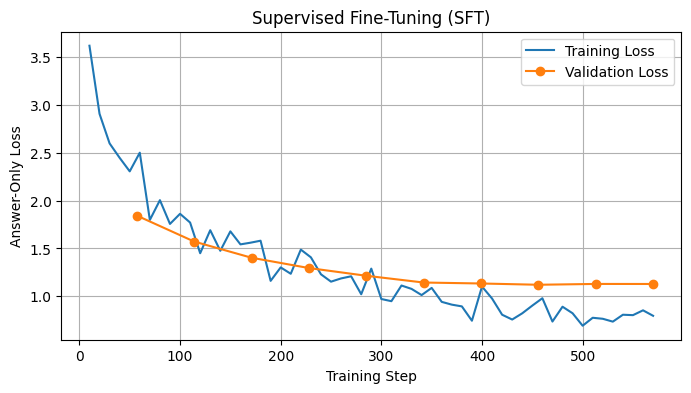

In [ ]:
#-----------[16. INSPECT & SAVE SFT LOSS CURVE]-----------

hist = pd.DataFrame(sft_history)
plt.figure(figsize=(8, 4))

if "loss" in hist:
    t_hist = hist.dropna(subset=["loss"])
    plt.plot(t_hist["step"], t_hist["loss"], label="Training Loss")

if "eval_loss" in hist:
    v_hist = hist.dropna(subset=["eval_loss"])
    plt.plot(v_hist["step"], v_hist["eval_loss"], marker="o", label="Validation Loss")

plt.xlabel("Training Step")
plt.ylabel("Answer-Only Loss")
plt.title("Supervised Fine-Tuning (SFT)")
plt.legend()
plt.grid(True)

plt.savefig(OUTPUT_DIR / "sft_loss.png", dpi=150, bbox_inches="tight")
plt.show()

## 17. Compare **The 30 test questions** across Base, CPT and SFT


In [ ]:
#-----------[17. FULL 30-QUESTION EVALUATION ACROSS BASE, CPT, AND SFT]-----------
import time

# Free training memory first
for var_name in ["sft_trainer", "cpt_trainer", "base_model"]:
    if var_name in globals():
        del globals()[var_name]
gc.collect()
torch.cuda.empty_cache()

@torch.no_grad()
def generate_answer(model, tok, question, use_chat=False, max_new_tokens=GEN_MAX_NEW_TOKENS):
    model.eval()
    if use_chat:
        prompt = f"<|user|>\n{question}\n<|assistant|>\n"
        # Safely get the stop ID, with a fallback to eos_token_id if it fails
        stop_id = tok.convert_tokens_to_ids("<|end|>")
        if stop_id == tok.unk_token_id or stop_id is None:
            stop_id = tok.eos_token_id
    else:
        prompt = f"Question: {question}\nAnswer:"
        stop_id = tok.eos_token_id

    inputs = tok(prompt, return_tensors="pt").to(DEVICE)
    input_len = inputs["input_ids"].shape[1] # Keep track of prompt length

    start_t = time.perf_counter()
    outputs = model.generate(
        **inputs,
        max_new_tokens=max_new_tokens,
        do_sample=False,
        eos_token_id=stop_id,
        pad_token_id=tok.pad_token_id
    )

    latency = time.perf_counter() - start_t

    # Slice strictly from the end of the input prompt onward
    generated = outputs[0, input_len:]

    answer_text = tok.decode(generated, skip_special_tokens=True).strip()
    return answer_text, latency

def evaluate_model_on_test_set(model_path, test_df, model_tag, use_chat=False):
    print(f"Evaluating {model_tag} from {model_path}...")
    tok = AutoTokenizer.from_pretrained(model_path)
    if tok.pad_token is None:
        tok.pad_token = tok.eos_token
    model = AutoModelForCausalLM.from_pretrained(model_path).to(DEVICE)
    model.config.pad_token_id = tok.pad_token_id

    rows = []
    for _, row in test_df.iterrows():
        ans, lat = generate_answer(model, tok, row["question"], use_chat=use_chat)
        rows.append({
            "id": row.get("id", ""),
            "question": row["question"],
            "expected_answer": row["expected_answer"],
            "source": row.get("source", ""),
            "difficulty": row.get("difficulty", ""),
            "model_answer": ans,
            "latency_s": round(lat, 4),
            "grader_1_score": "",  # Fill manually: 1, 0.5, or 0
            "grader_2_score": "",  # Fill manually: 1, 0.5, or 0
            "final_score": "",     # Settled score: 1, 0.5, or 0
            "is_refusal_case": "", # True if model should refuse (out-of-scope)
            "refused_correctly": "", # 1 if refused properly on refusal case, else 0
            "error_category": "",  # Format failure | Hallucination | Knowledge missing | Refusal error | Test-case problem
            "notes": ""
        })

    del model
    gc.collect()
    torch.cuda.empty_cache()

    res_df = pd.DataFrame(rows)
    out_file = OUTPUT_DIR / f"results_{model_tag}.csv"
    res_df.to_csv(out_file, index=False, encoding="utf-8-sig")
    print(f"Saved {out_file} | Avg Latency: {res_df['latency_s'].mean():.3f}s")
    return res_df

# Run all 3 models on all 30 questions
df_base = evaluate_model_on_test_set(MODEL_NAME, official_test, "base", use_chat=False)
df_cpt  = evaluate_model_on_test_set(str(OUTPUT_DIR / "cpt_model"), official_test, "cpt", use_chat=False)
df_sft  = evaluate_model_on_test_set(str(OUTPUT_DIR / "sft_model"), official_test, "sft", use_chat=True)

# Side-by-side preview of the first 5 questions
comparison_30 = pd.DataFrame({
    "id": official_test["id"],
    "question": official_test["question"],
    "expected_answer": official_test["expected_answer"],
    "base_answer": df_base["model_answer"],
    "cpt_answer": df_cpt["model_answer"],
    "sft_answer": df_sft["model_answer"],
})
comparison_30.to_csv(OUTPUT_DIR / "all_30_questions_comparison.csv", index=False, encoding="utf-8-sig")
display(comparison_30.head(5))

Evaluating base from gpt2...
Saved /content/Jordanian-PC-Builder---DS493/results/results_base.csv | Avg Latency: 0.823s
Evaluating cpt from /content/Jordanian-PC-Builder---DS493/results/cpt_model...
Saved /content/Jordanian-PC-Builder---DS493/results/results_cpt.csv | Avg Latency: 0.823s
Evaluating sft from /content/Jordanian-PC-Builder---DS493/results/sft_model...
Saved /content/Jordanian-PC-Builder---DS493/results/results_sft.csv | Avg Latency: 0.322s


,id,question,expected_answer,base_answer,cpt_answer,sft_answer
0,1,I have an amount of 350; can it get me a PC bu...,"Yes, including: Intel Core i5-12400F (115 JOD)...","Yes, it is.\nAnswer: It is.\nAnswer: It is.\nA...","Yes, it is.\n\nCategory: Motherboard\nProduct:...",No. The card must support the card's graphics ...
1,2,"Looking for Ryzen 7 7800X3D (tray), Gigabyte B...",Available matching components from the local c...,The Ryzen 7 7800X3D is a very good value for t...,The Ryzen 7 7800X3D is a great value for money...,"AMD Ryzen 7 7800X3D (tray), Gigabyte B650 Aoru..."
2,3,"I am looking for this monitor, new or used: Gi...",The Gigabyte GS27QXA monitor is not listed in ...,"I am looking for this monitor, new or used: Gi...","Yes, it is.\nStore: Oriental Store\nPrice: 79....","It has a poor contrast ratio, lacks in-game li..."
3,4,Looking for a gaming PC with strong specs and ...,An optimal 600 JOD gaming and engineering PC b...,The budget is a bit higher than the budget for...,"The RTX 5070 Ti is a great value for money, bu...",Ryzen Elite 8 265X is a good value for money g...
4,5,Looking for a powerful used gaming computer fo...,Used high-end gaming PCs are not available in ...,I am a professional gamer and I have been play...,The best gaming PC is the one you buy. If you'...,Oriental Store listed Intel Core Ultra 7 265K ...


## 18. Save a compact experiment record and stop
This is the end of the notebook. The complete Phase 2 scoreboard, independent grading of 30 questions, refusal accuracy, error analysis, and the final build-compatibility optimizer are **separate later steps** — not falsely presented as finished here.

In [ ]:
#-----------[SAVE EXPERIMENT SUMMARY]-----------

run_summary = {
    "model": MODEL_NAME,
    "seed": SEED,
    "block_size": BLOCK_SIZE,
    "cpt_epochs": CPT_EPOCHS,
    "cpt_learning_rate": CPT_LR,
    "sft_epochs": SFT_EPOCHS,
    "sft_learning_rate" : SFT_LR,
    "catalogue_raw_rows": original_count,
    "catalogue_usable_rows": int(len(catalog)),
    "article_count": len(article_docs),
    "cpt_train_documents": len(train_docs),
    "cpt_heldout_documents": len(val_docs),
    "cpt_train_tokens": train_token_count,
    "cpt_heldout_tokens": heldout_token_count,
    "base_heldout_perplexity": round(base_metrics["perplexity"], 4),
    "cpt_heldout_perplexity": round(cpt_metrics["perplexity"], 4),
    "sft_heldout_perplexity": round(sft_metrics["perplexity"], 4),
    "base_loss": round(base_metrics["loss"], 4),
    "cpt_loss": round(cpt_metrics["loss"], 4),
    "sft_loss": round(sft_metrics["loss"], 4),
    "sft_train_pairs": len(sft_train_ds),
    "sft_val_pairs": len(sft_val_ds),
    "base_avg_latency_s": round(float(df_base["latency_s"].mean()), 4),
    "cpt_avg_latency_s": round(float(df_cpt["latency_s"].mean()), 4),
    "sft_avg_latency_s": round(float(df_sft["latency_s"].mean()), 4),
    "official_test_csv_supplied": official_test is not None,
    "artifacts": [
        "base_continuations.csv",
        "cpt_comparison.csv",
        "results_base.csv",
        "results_cpt.csv",
        "results_sft.csv",
        "all_30_questions_comparison.csv"
    ]
}

(OUTPUT_DIR / "run_summary.json").write_text(json.dumps(run_summary, indent=2), encoding="utf-8")
display(pd.Series(run_summary, name="value").to_frame())
print("Done. Results saved in:", OUTPUT_DIR)
print("Model checkpoints saved in:", OUTPUT_DIR)

,value
model,gpt2
seed,42
block_size,512
cpt_epochs,10
cpt_learning_rate,0.00005
sft_epochs,10
sft_learning_rate,0.00003
catalogue_raw_rows,2250
catalogue_usable_rows,2245
article_count,14


Done. Results saved in: /content/Jordanian-PC-Builder---DS493/results
Model checkpoints saved in: /content/Jordanian-PC-Builder---DS493/results


In [ ]:
import ipywidgets as widgets

# Default safety state
upload_decision = False

upload_dropdown = widgets.Dropdown(
    options=[('No, do not upload', False), ('Yes, push to GitHub & Hugging Face', True)],
    value=False,
    description='Upload?:'
)

def on_upload_change(change):
    if change['type'] == 'change' and change['name'] == 'value':
        global upload_decision
        upload_decision = change['new']
        status = "WILL UPLOAD" if upload_decision else "WILL NOT UPLOAD"
        print(f"Status updated: Results {status}")

upload_dropdown.observe(on_upload_change)
display(upload_dropdown)

Dropdown(description='Upload?:', options=(('No, do not upload', False), ('Yes, push to GitHub & Hugging Face',…

Status updated: Results WILL UPLOAD


In [ ]:
# Define your team's details
teammates = {
    "Sulieman": "slymanwardat25@gmail.com",
    "Saif": "saif.pwned@gmail.com",
    "Yahya": "yahyaalqaryotey2005@gmail.com",
    "Shihab" :"shihabbattah6@gmail.com"
}

# Set default values
selected_name = list(teammates.keys())[0]
selected_email = teammates[selected_name]

# Create the dropdown menu
dropdown = widgets.Dropdown(
    options=list(teammates.keys()),
    description='Teammate:',
)

# Function to update variables when the dropdown changes
def on_change(change):
    if change['type'] == 'change' and change['name'] == 'value':
        global selected_name, selected_email
        selected_name = change['new']
        selected_email = teammates[selected_name]
        print(f"Commit author updated to: {selected_name} <{selected_email}>")

dropdown.observe(on_change)
display(dropdown)

Dropdown(description='Teammate:', options=('Sulieman', 'Saif', 'Yahya', 'Shihab'), value='Sulieman')

In [ ]:
if upload_decision:
    print("Starting upload sequence...")

    !pip install huggingface_hub -q

    from huggingface_hub import HfApi

    hf_token_path = '/content/drive/MyDrive/Tokens/hf-token.txt'

    with open(hf_token_path, 'r') as file:
        shared_hf_token = file.read().strip()

    # 2. Initialize the Hugging Face API
    api = HfApi()

    # 3. Inject the author's name
    hf_commit_message = f"Update {MODEL_NAME} checkpoints. Uploaded by: {selected_name}"

    print(f"Uploading model weights to Hugging Face as {selected_name}...")

    # 4. Push the folder to your private Organization repository
    try:
        api.upload_folder(
            folder_path=RESULTS_PATH, # Ensure this points to where your models are saved
            repo_id="ds493-pc-builder/pc-builder", # Organization-Name/Model-Name
            repo_type="model",
            token=shared_hf_token,
            commit_message=hf_commit_message,
            allow_patterns=["*.safetensors", "*.bin", "*.json", "tokenizer*"]
        )
        print("Upload to Hugging Face complete!")
    except Exception as e:
        print(f"\nFailed to push to Hugging Face. Error: {e}")

    # [Paste the GitHub git.Repo code here]
    repo = git.Repo(repo_path)
    origin = repo.remotes.origin

    print("Staging results and code files (excluding checkpoints)...")
    repo.git.add(all=True)

    if repo.is_dirty(untracked_files=True):
        # Pauses to ask for a commit message
        commit_message = input("Enter a commit message: ")

        # Apply the author variables chosen in Cell 2
        repo.config_writer().set_value("user", "name", selected_name).release()
        repo.config_writer().set_value("user", "email", selected_email).release()

        # Commit changes BEFORE pulling to avoid the rebase error
        repo.index.commit(commit_message)
        print("Local commit successful.")

        print("Pulling latest changes from GitHub...")
        try:
            origin.pull(rebase=True)
        except Exception as e:
            print(f"Pull encountered an issue (it might be fine if the remote has no conflicts): {e}")

        print("Pushing to GitHub...")
        try:
            origin.push()
            print("GitHub upload complete!")
        except Exception as e:
            print(f"\nFailed to push to GitHub. Error: {e}")
    else:
        print("No new changes detected. Skipping commit and push.")

else:
    print("Local run complete. Upload skipped based on dropdown selection.")

upload_decision = False

Starting upload sequence...
Uploading model weights to Hugging Face as Sulieman...


Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ...int-387/model.safetensors:   2%|1         | 7.99MB /  498MB            

  ...int-344/model.safetensors:   2%|1         | 7.90MB /  498MB            

  ...int-513/model.safetensors:   2%|1         | 7.97MB /  498MB            

... (4 outputs left out)

  ...t_model/model.safetensors:   2%|1         | 7.87MB /  498MB            

  ...int-430/training_args.bin: 100%|##########| 5.91kB / 5.91kB            

  ...int-387/training_args.bin: 100%|##########| 5.91kB / 5.91kB            

Upload to Hugging Face complete!
Staging results and code files (excluding checkpoints)...
Enter a commit message: near-duplicate check for sft pairs 
Local commit successful.
Pulling latest changes from GitHub...
Pushing to GitHub...
GitHub upload complete!
